# Первичный анализ данных

Анализируем структуру данных, целевую переменную, пропуски, основные статистики, категориальные признаки и потенциальные аномалии. 

In [18]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv('../data/raw/train.csv')
target = "Price"

print(f"Размер: {df.shape[0]:,} строк и {df.shape[1]} столбцов")
display(df.head())
display(df.dtypes.rename("Тип данных").to_frame())
print(f"Полных дубликатов строк: {df.duplicated().sum()}")

Размер: 10,000 строк и 20 столбцов


,Id,DistrictId,Rooms,Square,LifeSquare,KitchenSquare,Floor,HouseFloor,HouseYear,Ecology_1,Ecology_2,Ecology_3,Social_1,Social_2,Social_3,Healthcare_1,Helthcare_2,Shops_1,Shops_2,Price
0,11809,27,3.0,115.027311,NaN,10.0,4,10.0,2014,0.075424,B,B,11,3097,0,NaN,0,0,B,305018.871089
1,3013,22,1.0,39.832524,23.169223,8.0,7,8.0,1966,0.118537,B,B,30,6207,1,1183.0,1,0,B,177734.553407
2,8215,1,3.0,78.342215,47.671972,10.0,2,17.0,1988,0.025609,B,B,33,5261,0,240.0,3,1,B,282078.720850
3,2352,1,1.0,40.409907,NaN,1.0,10,22.0,1977,0.007122,B,B,1,264,0,NaN,0,1,B,168106.007630
4,13866,94,2.0,64.285067,38.562517,9.0,16,16.0,1972,0.282798,B,B,33,8667,2,NaN,0,6,B,343995.102962


,Тип данных
Id,int64
DistrictId,int64
Rooms,float64
Square,float64
LifeSquare,float64
KitchenSquare,float64
Floor,int64
HouseFloor,float64
HouseYear,int64
Ecology_1,float64


Полных дубликатов строк: 0


## Целевая переменная - `Price`

Посмотрим на распределение целевой переменной и его основные числовые характеристики.

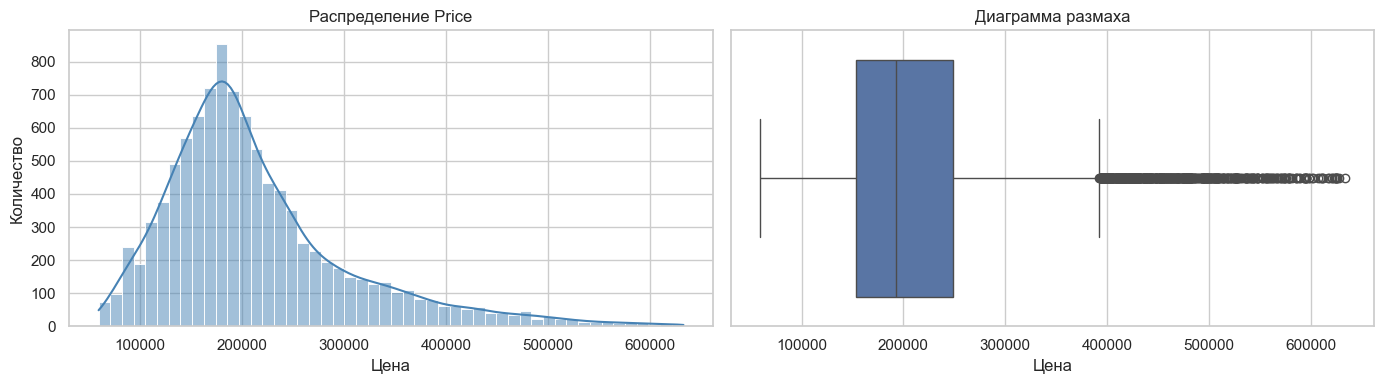

,count,mean,std,min,25%,50%,75%,max
Price,10000.0,214138.857399,92872.293865,59174.778028,153872.633942,192269.644879,249135.462171,633233.46657


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df[target], bins=50, kde=True, ax=axes[0], color="steelblue")
axes[0].set(title="Распределение Price", xlabel="Цена", ylabel="Количество")

sns.boxplot(x=df[target], ax=axes[1])
axes[1].set(title="Диаграмма размаха", xlabel="Цена")
plt.tight_layout()
plt.show()

display(df[target].describe().to_frame().T)

**Вывод по целевой переменной.** В выборке 10 000 объектов; `Price` заполнен для всех строк. Средняя цена составляет 214139, медианная - около 192270. Среднее выше медианы, распределение имеет правый хвост.

## Пропущенные значения

Покажем абсолютное число и долю пропусков.

,Пропуски,"Доля, %"
Healthcare_1,4798,47.98
LifeSquare,2113,21.13


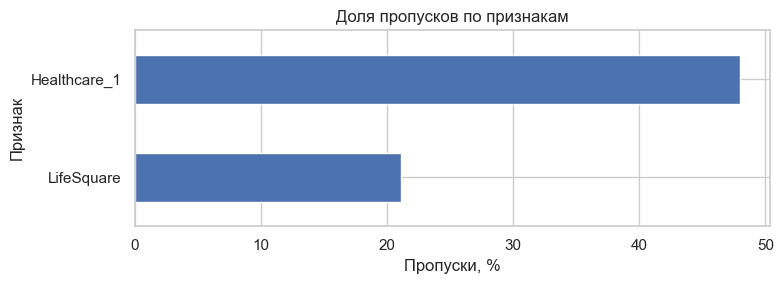

In [15]:
missing = pd.DataFrame({
    "Пропуски": df.isna().sum(),
    "Доля, %": df.isna().mean().mul(100),
})
missing = missing.loc[missing["Пропуски"].gt(0)].sort_values("Пропуски", ascending=False)
display(missing)

ax = missing["Доля, %"].sort_values().plot.barh(figsize=(8, 3))
ax.set(title="Доля пропусков по признакам", xlabel="Пропуски, %", ylabel="Признак")
plt.tight_layout()
plt.show()

**Вывод по пропускам.** Пропуски обнаружены в `Healthcare_1` (4798, 47.98%) и `LifeSquare` (2113; 21.13%). В остальных столбцах пропусков нет.     

## Базовые статистики числовых признаков

Посмотрим на основные статистики числевых признаков

In [19]:
numeric_features = df.select_dtypes(include="number").columns.drop(["Id", "DistrictId"])
display(df[numeric_features].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(2))


,Rooms,Square,LifeSquare,KitchenSquare,Floor,HouseFloor,HouseYear,Ecology_1,Social_1,Social_2,Social_3,Healthcare_1,Helthcare_2,Shops_1,Price
count,10000.00,10000.00,7887.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,5202.00,10000.00,10000.00,10000.00
mean,1.89,56.32,37.20,6.27,8.53,12.61,3990.17,0.12,24.69,5352.16,8.04,1142.90,1.32,4.23,214138.86
std,0.84,21.06,86.24,28.56,5.24,6.78,200500.26,0.12,17.53,4006.80,23.83,1021.52,1.49,4.81,92872.29
min,0.00,1.14,0.37,0.00,1.00,0.00,1910.00,0.00,0.00,168.00,0.00,0.00,0.00,0.00,59174.78
1%,1.00,29.72,2.86,0.00,1.00,0.00,1953.00,0.00,0.00,168.00,0.00,30.00,0.00,0.00,73901.96
25%,1.00,41.77,22.77,1.00,4.00,9.00,1974.00,0.02,6.00,1564.00,0.00,350.00,0.00,1.00,153872.63
50%,2.00,52.51,32.78,6.00,7.00,13.00,1977.00,0.08,25.00,5285.00,2.00,900.00,1.00,3.00,192269.64
75%,2.00,65.90,45.13,9.00,12.00,17.00,2001.00,0.20,36.00,7227.00,5.00,1548.00,2.00,6.00,249135.46
99%,4.00,117.86,95.65,16.00,24.00,25.00,2018.01,0.46,74.00,19083.00,141.00,4508.00,5.00,23.00,526300.67
max,19.00,641.07,7480.59,2014.00,42.00,117.00,20052011.00,0.52,74.00,19083.00,141.00,4849.00,6.00,23.00,633233.47


## Категориальные признаки и уникальные значения

Для строковых категориальных столбцов выведем все категории и их соотношение

Категориальные признаки:

Ecology_2 (2 уникальных значений):


,Количество
Ecology_2,
B,9903
A,97



Ecology_3 (2 уникальных значений):


,Количество
Ecology_3,
B,9725
A,275



Shops_2 (2 уникальных значений):


,Количество
Shops_2,
B,9175
A,825



DistrictId: 205 уникальных районов; 10 наиболее частых:


,Количество
DistrictId,
27,851
1,652
23,565
6,511
9,294
62,247
30,228
58,179
53,174


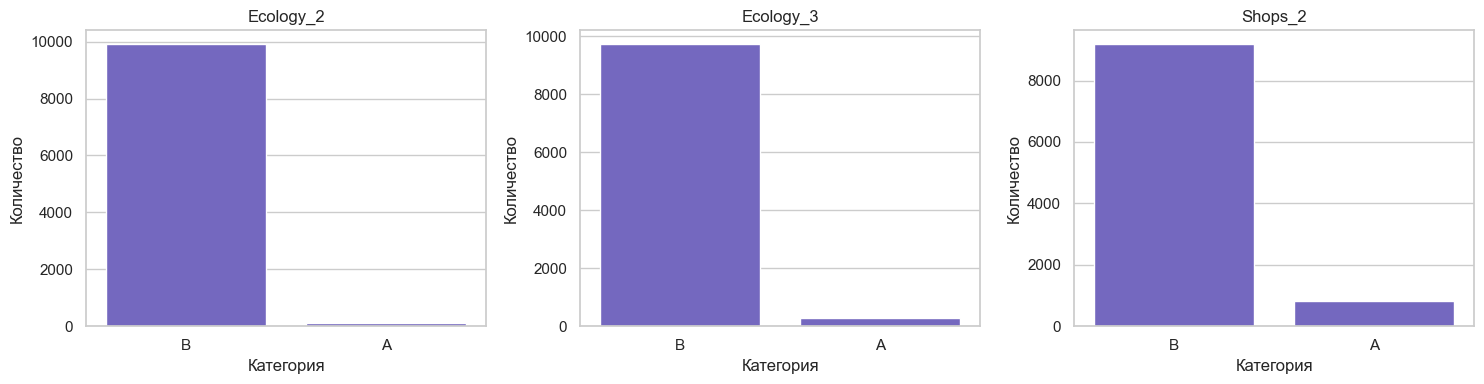

In [5]:
categorical_features = df.select_dtypes(include=["object", "category"]).columns.tolist()
print("Категориальные признаки:")
for column in categorical_features:
    print(f"\n{column} ({df[column].nunique(dropna=False)} уникальных значений):")
    display(df[column].value_counts(dropna=False).rename("Количество").to_frame())

if "DistrictId" in df.columns:
    print(f"\nDistrictId: {df['DistrictId'].nunique()} уникальных районов; 10 наиболее частых:")
    display(df["DistrictId"].value_counts().head(10).rename("Количество").to_frame())

if categorical_features:
    fig, axes = plt.subplots(1, len(categorical_features), figsize=(5 * len(categorical_features), 4))
    if len(categorical_features) == 1:
        axes = [axes]
    for ax, column in zip(axes, categorical_features):
        sns.countplot(data=df, x=column, order=df[column].value_counts().index, ax=ax, color="slateblue")
        ax.set(title=column, xlabel="Категория", ylabel="Количество")
    plt.tight_layout()
    plt.show()

**Вывод по категориям.** `Ecology_2`, `Ecology_3` и `Shops_2` имеют по две категории (`A` и `B`); категория `B` преобладает во всех трёх признаках.

## Потенциальные выбросы и аномалии

Сначала сравним числовые распределения на диаграммах размаха. Затем проверим несколько предметных несогласованностей: нулевое/очень большое число комнат, жилую или кухонную площадь больше общей, этаж выше этажности дома и год постройки в будущем относительно 2026 года. Это флаги для проверки, а не автоматическое удаление записей.

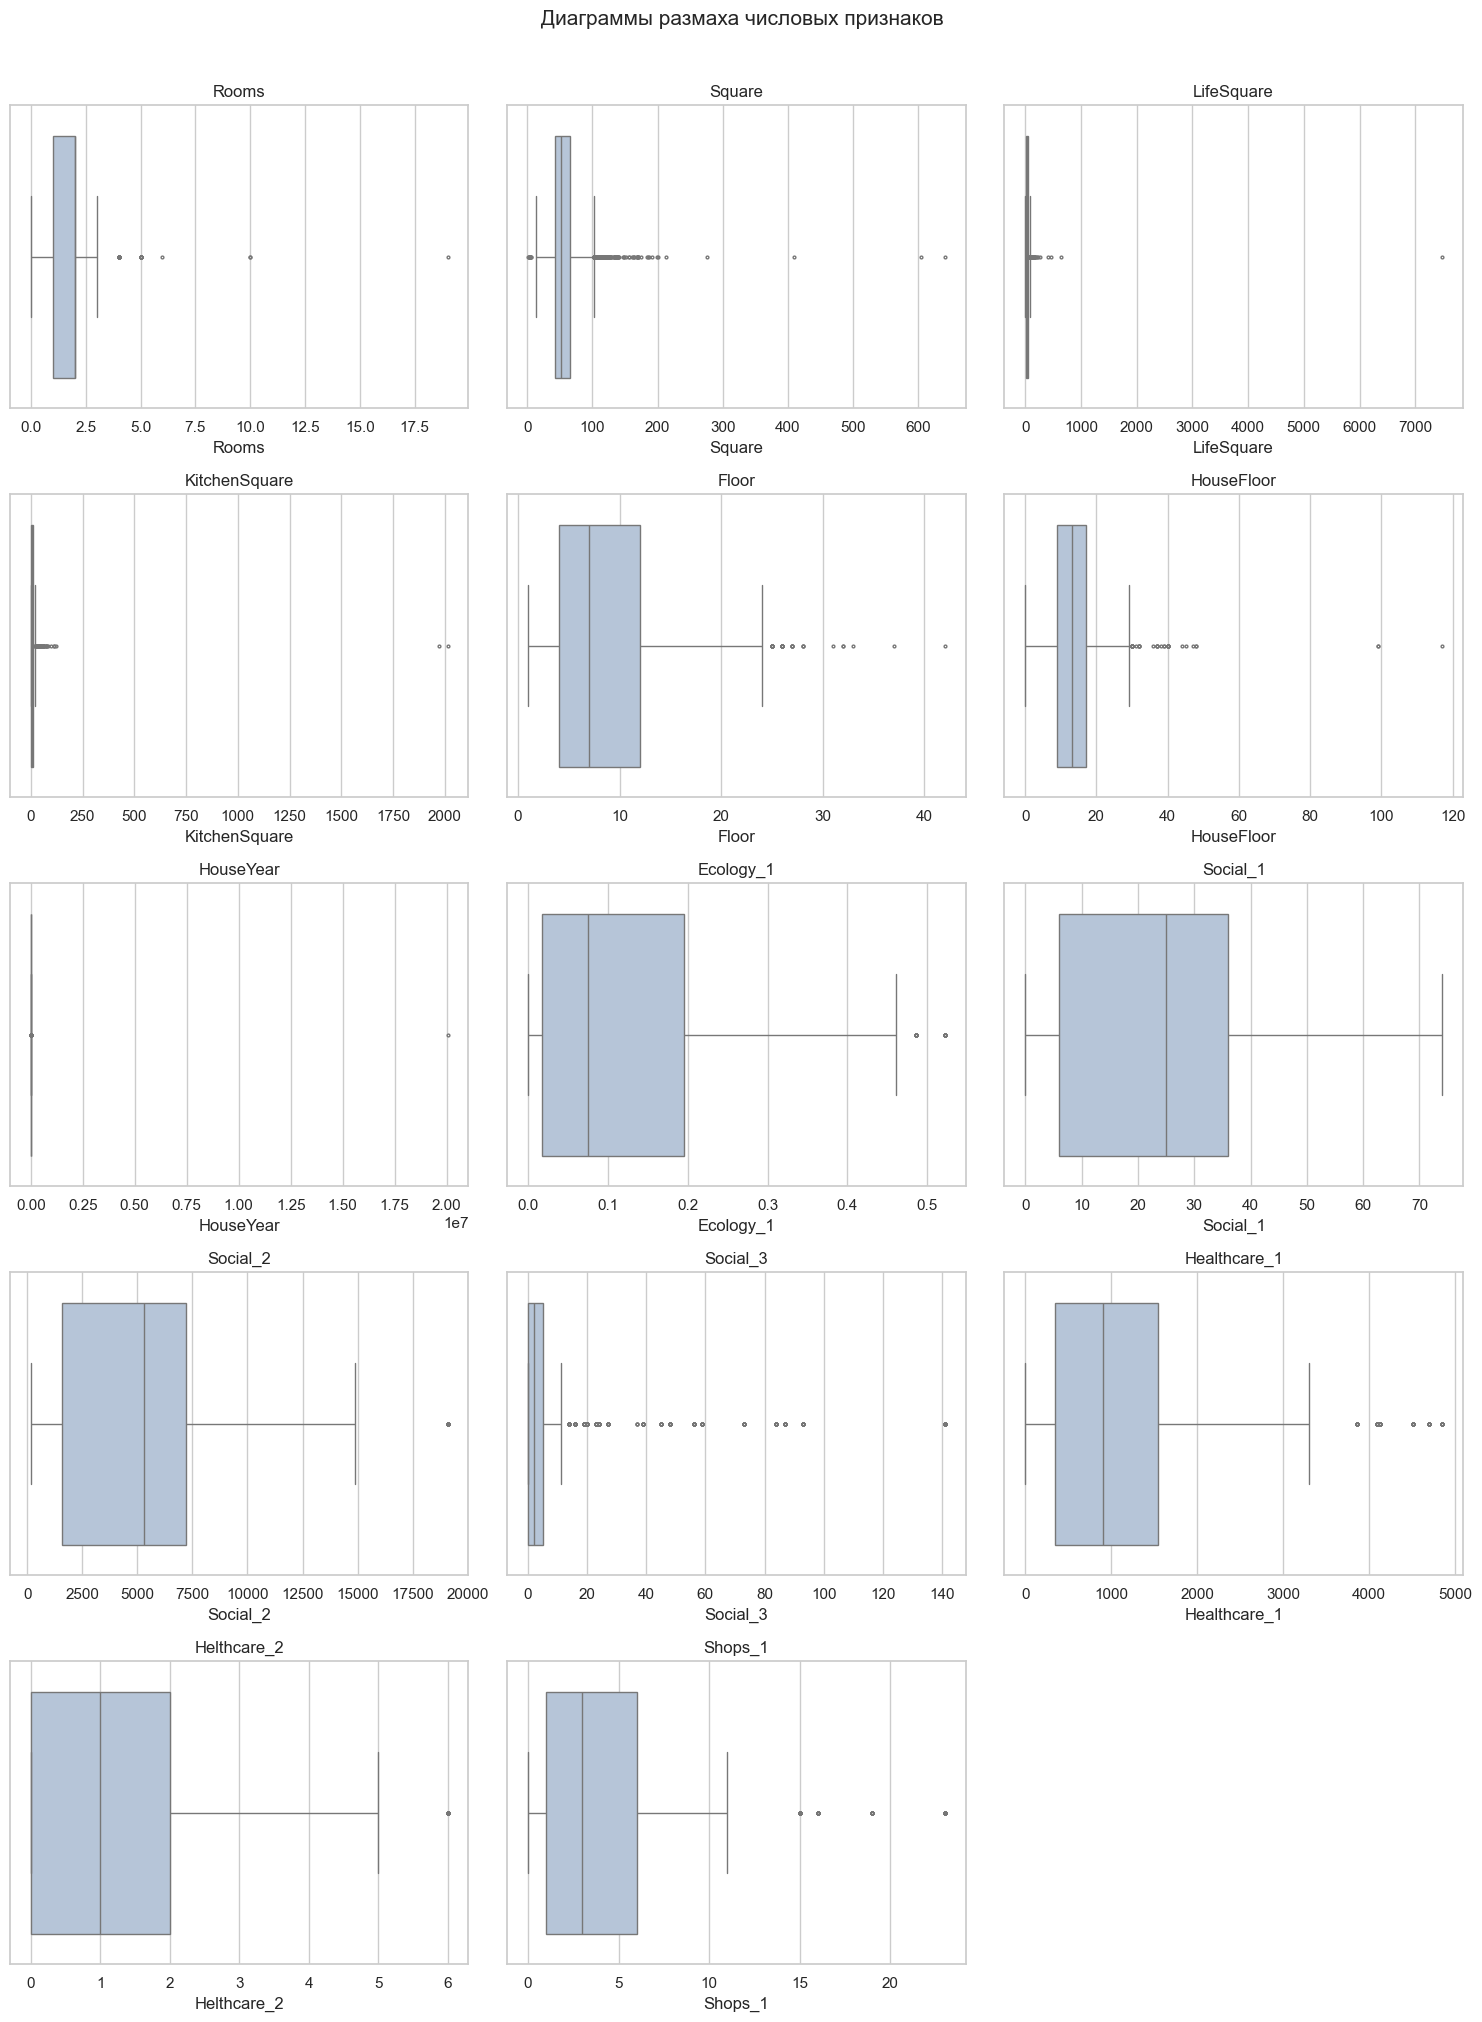

,Число строк с флагом
Floor > HouseFloor,1825
LifeSquare > Square,482
Rooms = 0,8
KitchenSquare > Square,4
Rooms > 6,3
HouseYear > 2026,2


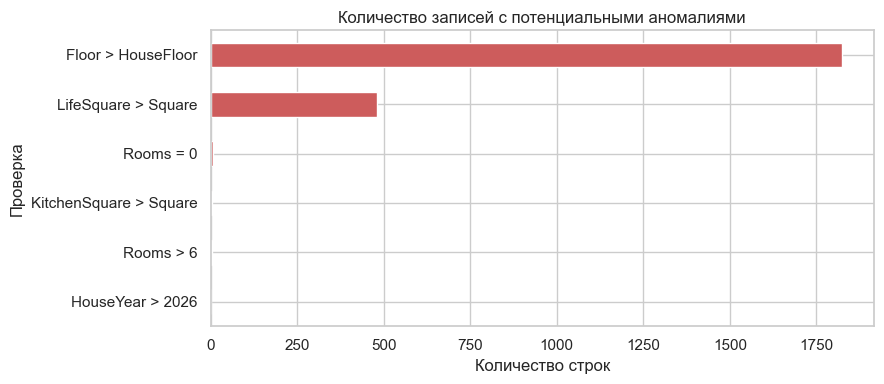

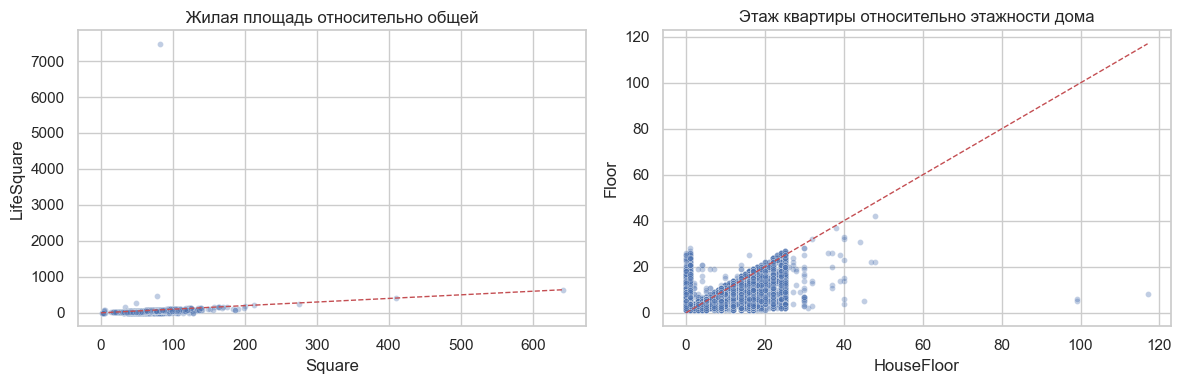

In [6]:
plot_features = [column for column in numeric_features if column != target]
ncols = 3
nrows = (len(plot_features) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()
for ax, column in zip(axes, plot_features):
    sns.boxplot(x=df[column], ax=ax, color="lightsteelblue", fliersize=2)
    ax.set_title(column)
for ax in axes[len(plot_features):]:
    ax.set_visible(False)
fig.suptitle("Диаграммы размаха числовых признаков", y=1.01, fontsize=15)
plt.tight_layout()
plt.show()

domain_flags = pd.DataFrame({
    "Rooms = 0": df["Rooms"].eq(0),
    "Rooms > 6": df["Rooms"].gt(6),
    "LifeSquare > Square": df["LifeSquare"].gt(df["Square"]),
    "KitchenSquare > Square": df["KitchenSquare"].gt(df["Square"]),
    "Floor > HouseFloor": df["Floor"].gt(df["HouseFloor"]),
    "HouseYear > 2026": df["HouseYear"].gt(2026),
})
flag_counts = domain_flags.sum().sort_values(ascending=False)
display(flag_counts.rename("Число строк с флагом").to_frame())
ax = flag_counts.sort_values().plot.barh(figsize=(9, 4), color="indianred")
ax.set(title="Количество записей с потенциальными аномалиями", xlabel="Количество строк", ylabel="Проверка")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=df, x="Square", y="LifeSquare", alpha=0.35, s=18, ax=axes[0])
axes[0].plot([0, df["Square"].max()], [0, df["Square"].max()], "r--", linewidth=1)
axes[0].set(title="Жилая площадь относительно общей", xlabel="Square", ylabel="LifeSquare")
sns.scatterplot(data=df, x="HouseFloor", y="Floor", alpha=0.35, s=18, ax=axes[1])
limit = max(df["HouseFloor"].max(), df["Floor"].max())
axes[1].plot([0, limit], [0, limit], "r--", linewidth=1)
axes[1].set(title="Этаж квартиры относительно этажности дома", xlabel="HouseFloor", ylabel="Floor")
plt.tight_layout()
plt.show()

**Вывод по аномалиям.** Наиболее заметные потенциальные проблемы по предметным проверкам:

`HouseYear` у двух объектов больше 2026 года;

у 482 объектов `LifeSquare > Square`;

у 1 825 объектов `Floor > HouseFloor`; 

у четырёх объектов `KitchenSquare > Square`; 

у восьми указано ноль комнат и у трёх — больше шести. 

Максимумы отдельных признаков также выглядят подозрительно (например, `Square` около 641, `LifeSquare` около 7 481, `KitchenSquare` около 2 014 и `HouseFloor` до 117).